<a href="https://colab.research.google.com/github/Dishantchd/DS-practical/blob/main/Ds_practical10/Practical10_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Practical 10**

**PCA**

Description
Please work on wine dataset:

 1. Display the Basic Statistics using describe ()

 2. Boxplot by output labels/classes

 3. Scatterplot using two variable

4. Plot Co-Variance Matrix

5. Data Scaling

6. Show better class separation using principal components

**The wine dataset**

Description of Wine Dataset

**Introduction**

The Wine Recognition Dataset is a collection of chemical analysis results of wines derived from three different wine classes.

This dataset contains information about the chemical properties of wine, such as alcohol content, malic acid, ash, magnesium, flavanoids, colour intensity, and proline.

The main purpose of this dataset is to analyse the chemical characteristics of wine and identify differences between three wine classes using statistical analysis, data visualization, and machine learning techniques.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("Wine dataset.csv")

print(df.head())
print(df.shape)
print(df.info())

   class  Alcohol  Malic acid   Ash  Alcalinity of ash  Magnesium  \
0      1    14.23        1.71  2.43               15.6        127   
1      1    13.20        1.78  2.14               11.2        100   
2      1    13.16        2.36  2.67               18.6        101   
3      1    14.37        1.95  2.50               16.8        113   
4      1    13.24        2.59  2.87               21.0        118   

   Total phenols  Flavanoids  Nonflavanoid phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color intensity   Hue  OD280/OD315 of diluted wines  Proline   
0             5.64  1.04                          3.92      1065  
1             4.38  1.05

In [ ]:
print("Classes:", df['class'].unique())


Classes: [1 2 3]


Explanation:

178 rows represent 178 wine samples.

13 columns represent different chemical features.

Class represents the wine category.

There are 3 different wine classes.

In [ ]:

print(df.describe())

            class     Alcohol  Malic acid         Ash  Alcalinity of ash  \
count  178.000000  178.000000  178.000000  178.000000         178.000000   
mean     1.938202   13.000618    2.336348    2.366517          19.494944   
std      0.775035    0.811827    1.117146    0.274344           3.339564   
min      1.000000   11.030000    0.740000    1.360000          10.600000   
25%      1.000000   12.362500    1.602500    2.210000          17.200000   
50%      2.000000   13.050000    1.865000    2.360000          19.500000   
75%      3.000000   13.677500    3.082500    2.557500          21.500000   
max      3.000000   14.830000    5.800000    3.230000          30.000000   

        Magnesium  Total phenols  Flavanoids  Nonflavanoid phenols  \
count  178.000000     178.000000  178.000000            178.000000   
mean    99.741573       2.295112    2.029270              0.361854   
std     14.282484       0.625851    0.998859              0.124453   
min     70.000000       0.980000   

/tmp/ipykernel_848/4162033308.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='class', y='Alcohol',
/tmp/ipykernel_848/4162033308.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='class', y='Malic acid',
/tmp/ipykernel_848/4162033308.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='class', y='Color intensity',


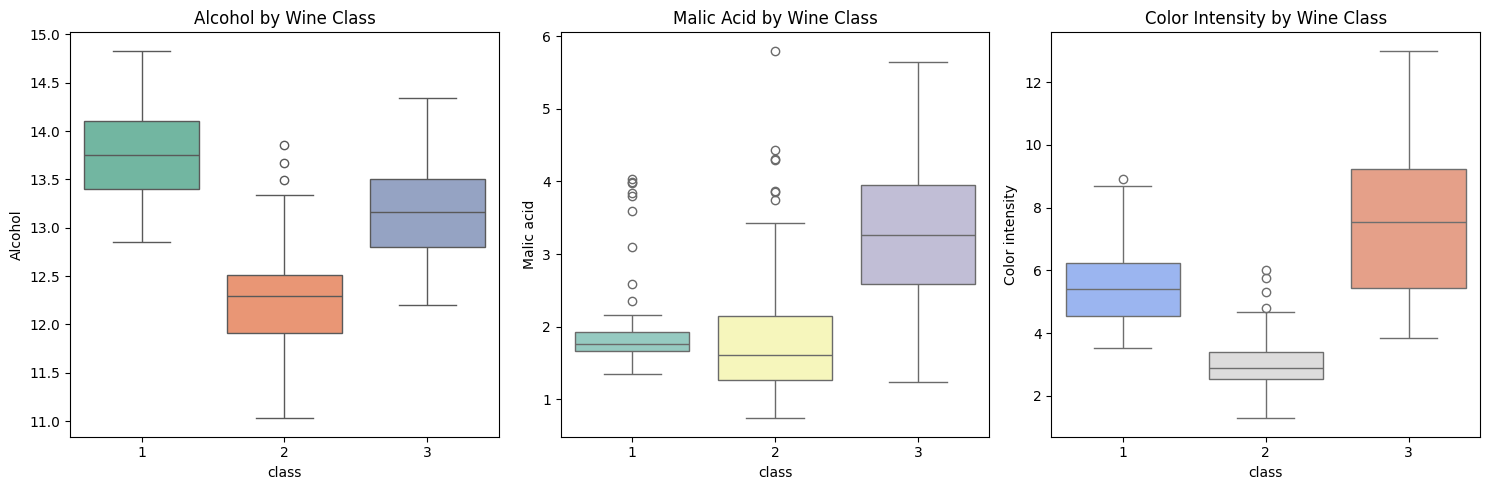

In [ ]:
plt.figure(figsize=(15, 5))

# Alcohol
plt.subplot(1, 3, 1)
sns.boxplot(data=df, x='class', y='Alcohol',
            palette='Set2')
plt.title('Alcohol by Wine Class')

# Malic Acid
plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='class', y='Malic acid',
            palette='Set3')
plt.title('Malic Acid by Wine Class')

# Color Intensity
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='class', y='Color intensity',
            palette='coolwarm')
plt.title('Color Intensity by Wine Class')

plt.tight_layout()
plt.show()

Interpretation:

Each box represents the distribution of a feature.

The middle line represents the median.

The upper and lower edges represent the 75th and 25th percentiles.

Dots outside the whiskers represent possible outliers.

Different distributions indicate that chemical properties vary between wine classes.

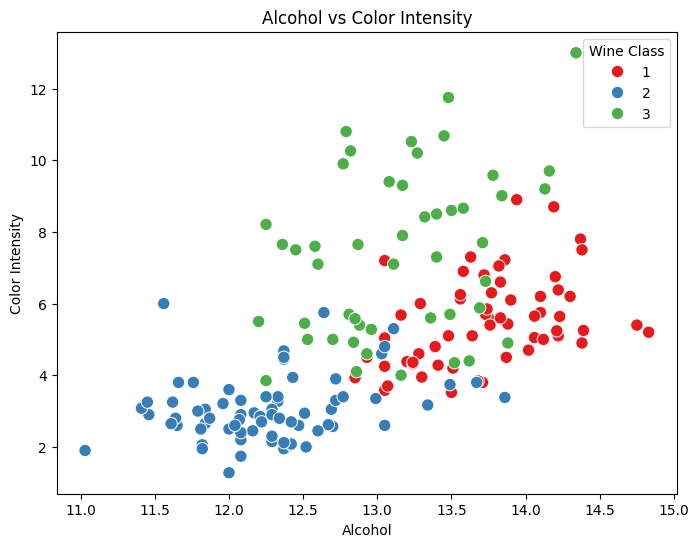

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Alcohol',
    y='Color intensity',
    hue='class',
    palette='Set1',
    s=80
)

plt.title('Alcohol vs Color Intensity')
plt.xlabel('Alcohol')
plt.ylabel('Color Intensity')

plt.legend(title='Wine Class')

plt.show()

The scatterplot shows the relationship between Alcohol and Color Intensity.

X-axis represents Alcohol content.
Y-axis represents Color Intensity.
Each dot represents one wine sample.
Different colours represent different wine classes.

Observations:

Class 1 (red) generally has higher alcohol content and medium-to-high color intensity.
Class 2 (blue) generally has lower alcohol content and lower color intensity.
Class 3 (green) generally has higher color intensity.

The scatterplot shows that different wine classes form partially separate groups based on their chemical properties. However, some observations overlap.

Therefore, Alcohol and Color Intensity can help distinguish between wine classes, but these two features alone do not provide complete separation

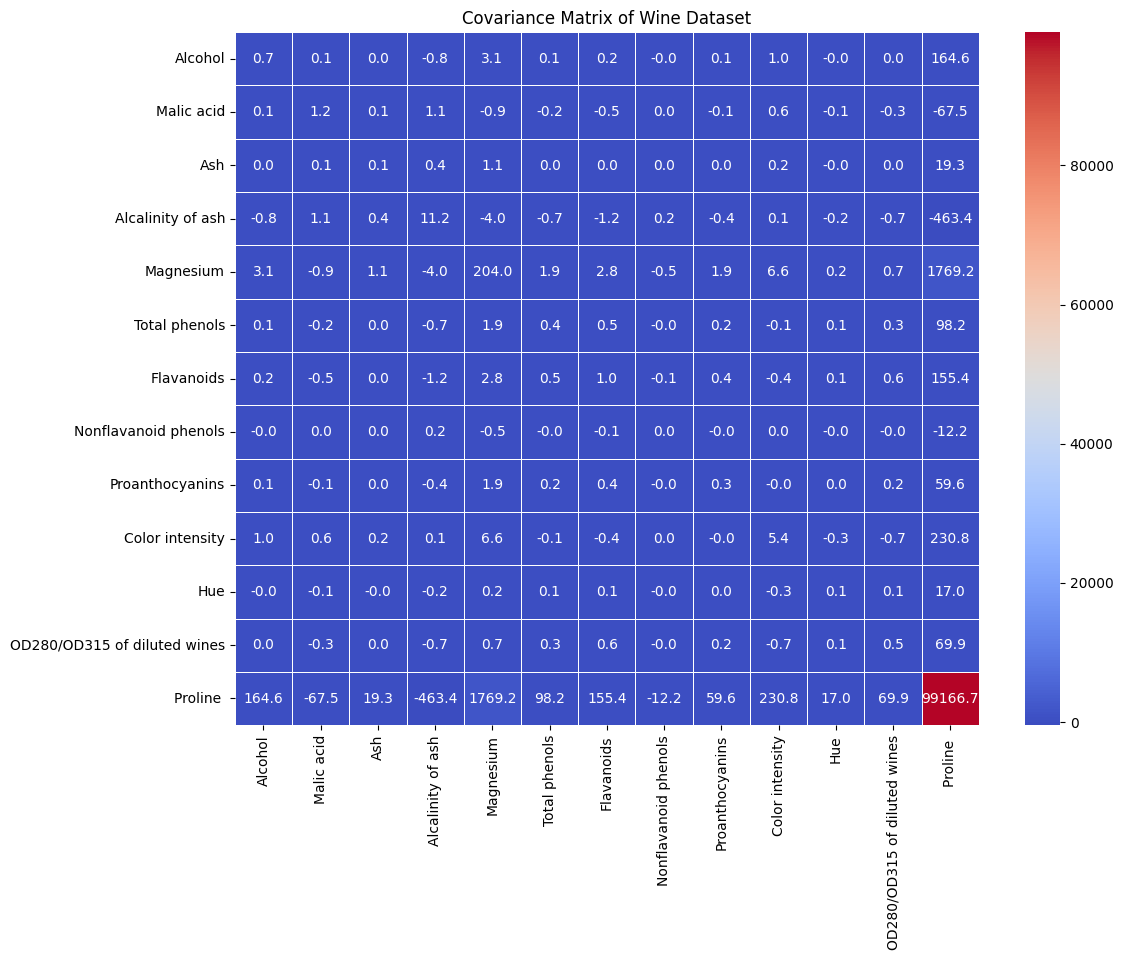

In [ ]:
# Select only numerical features
X = df.drop('class', axis=1)

# Calculate covariance matrix
cov_matrix = X.cov()

# Plot covariance heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    cov_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.1f',
    linewidths=0.5
)

plt.title('Covariance Matrix of Wine Dataset')

plt.show()

In [ ]:
#6. Data Scaling Using StandardScaler
# Separate features and target
X = df.drop('class', axis=1)
y = df['class']

# Apply StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Display first five rows
print(scaled_df.head())

# Check mean and standard deviation
print("\nMean after scaling:")
print(scaled_df.mean().round(2))

print("\nStandard Deviation after scaling:")
print(scaled_df.std().round(2))

    Alcohol  Malic acid       Ash  Alcalinity of ash  Magnesium  \
0  1.518613   -0.562250  0.232053          -1.169593   1.913905   
1  0.246290   -0.499413 -0.827996          -2.490847   0.018145   
2  0.196879    0.021231  1.109334          -0.268738   0.088358   
3  1.691550   -0.346811  0.487926          -0.809251   0.930918   
4  0.295700    0.227694  1.840403           0.451946   1.281985   

   Total phenols  Flavanoids  Nonflavanoid phenols  Proanthocyanins  \
0       0.808997    1.034819             -0.659563         1.224884   
1       0.568648    0.733629             -0.820719        -0.544721   
2       0.808997    1.215533             -0.498407         2.135968   
3       2.491446    1.466525             -0.981875         1.032155   
4       0.808997    0.663351              0.226796         0.401404   

   Color intensity       Hue  OD280/OD315 of diluted wines  Proline   
0         0.251717  0.362177                      1.847920  1.013009  
1        -0.293321  0.406051

In [ ]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['class'] = y.values

print(pca_df.head())

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(sum(pca.explained_variance_ratio_) * 100)

        PC1       PC2  class
0  3.316751  1.443463      1
1  2.209465 -0.333393      1
2  2.516740  1.031151      1
3  3.757066  2.756372      1
4  1.008908  0.869831      1

Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Variance Explained:
55.40633835693527


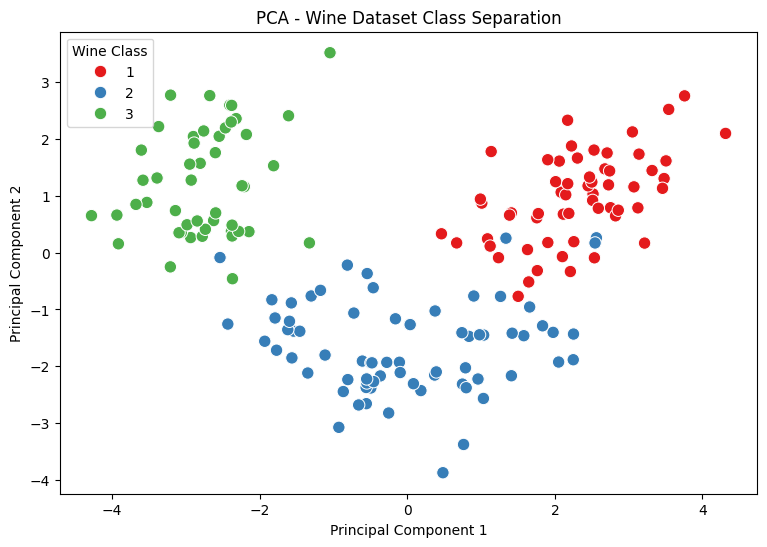

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='class',
    palette='Set1',
    s=80
)

plt.title('PCA - Wine Dataset Class Separation')

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(title='Wine Class')

plt.show()